# Qwen3-VL-4B-Instruct 하자 짧은 설명 생성 — 인터랙티브 검증

**스파이크/검증용 코드입니다. 프로덕션 코드가 아닙니다.**

CH009 계획(`.claude/plans/ai/CH009-quality-defect-vlm.md`) "1. 후보 선정" ~ "2. 검증 축"에
대응한다. `verify_qwen3vl.py`로 1차 스모크 테스트(가동 여부)는 이미 통과했다 — 이 노트북은
그 다음 단계, 즉 **셀 단위로 결과를 보면서 크롭 크기·프롬프트 문구를 바로 바꿔볼 수 있게**
만든 버전이다.

### 이전 스모크 테스트에서 확인된 것

- `Qwen/Qwen3-VL-4B-Instruct`가 `qual` conda 환경(RTX 4070 Laptop, VRAM 8GB)에서 **4bit
  양자화(bitsandbytes nf4)**로 정상 로드된다 — VRAM 사용 약 2.7GB(peak 2.87GB), SAM3
  (fp16 ~1.7GB)와 합쳐도 8GB 예산에 여유가 있다.
- 한국어 프롬프트에 **번역 단계 없이 직접 한국어 문장**을 생성한다.
- 다만 SAM3 실제 bbox(14~46px 폭의 아주 작은 크롭)로 테스트하니 출력이 **입력 라벨을 그대로
  재진술하는 수준**(예: "얼룩이 있는 부분이 확대되어 보입니다")에 그쳤다 — 색상·모양·범위 같은
  구체적 시각 정보가 거의 없었다.

### 이 노트북이 확인하려는 것

1. 크롭을 더 크게(§3 `MIN_CROP_SIZE`) 하면 출력이 더 구체적으로 나아지는가
2. 프롬프트에서 라벨을 미리 알려주는 것과, 안 알려주고 순수하게 보이는 것만 묻는 것의 차이
   (§3 `PROMPT_VARIANTS`)
3. 이미지·finding을 바꿔가며(§5) 같은 경향이 재현되는가

### 실행 순서

셀을 위에서 아래로 한 번 실행한 뒤, §5(단일 finding 재실험) 셀만 값을 바꿔가며 반복 실행하면
된다 — 모델은 §2에서 한 번만 로드하고 계속 재사용한다.

## 0. 의존성 설치

`requirements-vlm.txt`를 설치한다. `qual` conda 환경(SAM3 스파이크와 공유, transformers>=5.0)에
`bitsandbytes`만 추가로 설치하면 된다.

In [ ]:
%pip install -q -r requirements-vlm.txt

## 0-1. CUDA / GPU 확인

4bit 양자화도 GPU 전제라 CUDA가 없으면 이 스파이크는 사실상 못 돈다.

In [ ]:
import torch

print(f"torch          : {torch.__version__}")
print(f"cuda available : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    _props = torch.cuda.get_device_properties(0)
    print(f"gpu            : {_props.name}")
    print(f"total VRAM     : {_props.total_memory / 1024**3:.2f} GB")
    print(f"cuda runtime   : {torch.version.cuda}")
else:
    print("[주의] CUDA를 찾지 못했습니다. 4bit 양자화도 GPU 전제라 CPU로는 불가능합니다.")

torch          : 2.13.0+cu130
cuda available : True
gpu            : NVIDIA GeForce RTX 4070 Laptop GPU
total VRAM     : 8.00 GB
cuda runtime   : 13.0


## 0-2. 설정 상수

`model_selection/model_registry.py` 관례대로 **바꿔 끼울 값을 한곳에 모은다.** 크롭
크기·프롬프트 문구·대상 이미지는 전부 여기(또는 §5 재실험 셀)에서만 고치면 된다.

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, "..")  # qc_shared.py(QUAL/), sam3-condition-check 산출물 재사용
from qc_shared import IMAGE_EXTS, pad_bbox_clamped, use_korean_font  # noqa: E402

from loaders import build_defect_prompt, generate_from_image, load_qwen_vl  # noqa: E402
from model_registry import ACTIVE_QUANTIZATION, ACTIVE_VLM, VLM_MODELS  # noqa: E402

MODEL_ID = VLM_MODELS[ACTIVE_VLM]

# --- 실험 대상 이미지/크롭 --- 여기 값만 바꾸면 다른 이미지·다른 크롭 설정으로 재실행된다.
# sam3-condition-check/outputs/qc_summary.json에 있는 이미지 중 하자가 있는 것들:
# denim(3), levis_patch(16), scratch(7), small_pro(6), black_washed(2), logo_test(1)
IMAGE_STEM = "scratch"  # sample_images/<stem>.* + outputs/<stem>_qc.json
CROP_PAD_RATIO = 0.6  # bbox 대비 여백 비율(sam3_qc_test.ipynb §8과 같은 상수)
MIN_CROP_SIZE = 160  # 1차 스모크 테스트(14~46px 크롭)가 정보 부족으로 보여 최소 크기를 보장

# --- 프롬프트 실험 --- 키만 바꾸면 다른 프롬프트로 스왑된다(model_selection 관례와 동일).
# TO-DO: One-shot / Few-shot 테스트 진행 (답변 형태 고정)
PROMPT_VARIANTS = {
    "default": None,  # None이면 loaders.build_defect_prompt() 그대로 사용(라벨을 미리 알려줌)
    "no_label_hint": (
        "이 이미지는 중고 의류의 한 부분을 확대한 사진입니다. "
        "표면에 보이는 상태(색, 모양, 얼룩/손상 여부 등)를 본 대로 한국어 한 문장으로 "
        "설명해 주세요. 보이지 않는 내용은 지어내지 마세요."
    ),
    "visual_detail": (
        "이 이미지는 중고 의류의 '{label}' 하자 부분을 확대한 사진입니다. "
        "색상, 모양, 크기, 위치적 특징 중 실제로 보이는 것만 한국어 한 문장으로 구체적으로 "
        "설명해 주세요. 보이지 않는 내용은 지어내지 마세요."
    ),
}
ACTIVE_PROMPT_VARIANT = "default"


def expand_bbox_to_min_size(bbox, pad_ratio, min_size, image_size):
    """pad_bbox_clamped로 여백을 준 뒤, 결과가 min_size보다 작으면 중심 기준으로 더 넓힌다."""
    x1, y1, x2, y2 = pad_bbox_clamped(bbox, pad_ratio, image_size)
    img_w, img_h = image_size
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    half_w = max((x2 - x1) / 2, min_size / 2)
    half_h = max((y2 - y1) / 2, min_size / 2)
    return [
        max(0, int(cx - half_w)),
        max(0, int(cy - half_h)),
        min(img_w, int(cx + half_w)),
        min(img_h, int(cy + half_h)),
    ]


def build_prompt(label):
    variant = PROMPT_VARIANTS[ACTIVE_PROMPT_VARIANT]
    if variant is None:
        return build_defect_prompt(label)
    return variant.format(label=label) if "{label}" in variant else variant


use_korean_font()
print(f"model_id={MODEL_ID}  quantization={ACTIVE_QUANTIZATION}")
print(f"prompt_variant={ACTIVE_PROMPT_VARIANT}")
print(f"crop: pad_ratio={CROP_PAD_RATIO}  min_size={MIN_CROP_SIZE}px")

model_id=Qwen/Qwen3-VL-4B-Instruct  quantization=4bit
prompt_variant=default
crop: pad_ratio=0.6  min_size=160px


## 1. 모델 로드 (VRAM 실측)

한 번만 실행한다 — 이후 셀들은 이미 로드된 `bundle`을 재사용한다.

In [3]:
import time


def _vram_report(tag):
    """(allocated_MB, peak_MB)를 찍고 반환. sam3_qc_test.ipynb의 관례와 동일."""
    if not torch.cuda.is_available():
        print(f"{tag:<20} (CPU 모드 - VRAM 측정 없음)")
        return (0.0, 0.0)
    alloc = torch.cuda.memory_allocated() / 1024**2
    peak = torch.cuda.max_memory_allocated() / 1024**2
    print(f"{tag:<20} allocated={alloc:9.1f} MB ({alloc / 1024:.2f} GB)   peak={peak:9.1f} MB")
    return (alloc, peak)


if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
_vram_report("로드 전")

_t0 = time.time()
bundle = load_qwen_vl(MODEL_ID, quantization=ACTIVE_QUANTIZATION)
print(f"로드 소요: {time.time() - _t0:.1f}s")
_vram_report("로드 후")

로드 전                 allocated=      0.0 MB (0.00 GB)   peak=      0.0 MB


c:\Users\SSAFY\miniforge3\envs\qual\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W0731 17:23:06.726000 40080 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
Loading weights: 100%|██████████| 713/713 [00:06<00:00, 102.15it/s]


로드 소요: 29.6s
로드 후                 allocated=   2776.0 MB (2.71 GB)   peak=   2796.4 MB


(2776.03857421875, 2796.36572265625)

## 2. 데이터 로드 — 이미지 + SAM3 findings

`IMAGE_STEM`이 가리키는 이미지와, 같은 이름의 SAM3 산출물(`<stem>_qc.json`)을 불러온다.

In [ ]:
import json

from PIL import Image

SAMPLE_DIR = Path("../sam3-condition-check/sample_images")
OUTPUT_DIR = Path("../sam3-condition-check/outputs/masking")


def find_image_path(stem):
    for ext in IMAGE_EXTS:
        p = SAMPLE_DIR / f"{stem}{ext}"
        if p.is_file():
            return p
    raise FileNotFoundError(f"{stem} 이미지를 {SAMPLE_DIR}에서 못 찾았습니다")


image_path = find_image_path(IMAGE_STEM)
findings_path = OUTPUT_DIR / f"{IMAGE_STEM}_qc.json"
findings = json.loads(findings_path.read_text(encoding="utf-8"))
image = Image.open(image_path).convert("RGB")

print(
    f"이미지: {image_path.name}  size={image.size}  "
    f"verdict={findings['verdict']}  findings={len(findings['instances'])}"
)
for inst in findings["instances"]:
    print(f"  [{inst['no']}] {inst['label']:<6} conf={inst['confidence']:.2f}  bbox={inst['bbox']}")

이미지: scratch.jpg  size=(620, 620)  verdict=FAIL  findings=7
  [1] 얼룩     conf=0.91  bbox=[175, 143, 263, 211]
  [2] 얼룩     conf=0.89  bbox=[352, 302, 432, 326]
  [3] 얼룩     conf=0.88  bbox=[162, 360, 262, 432]
  [4] 얼룩     conf=0.88  bbox=[216, 190, 261, 213]
  [5] 얼룩     conf=0.83  bbox=[201, 243, 250, 253]
  [6] 얼룩     conf=0.51  bbox=[223, 298, 232, 317]
  [7] 구멍     conf=0.30  bbox=[303, 153, 317, 184]


## 3. 크롭 미리보기

모델에게 실제로 넘어갈 크롭 이미지를 먼저 눈으로 확인한다 — 텍스트 결과만 보고 판단하면
"크롭이 원래 이 정도로 작았는지"를 놓치기 쉽다.

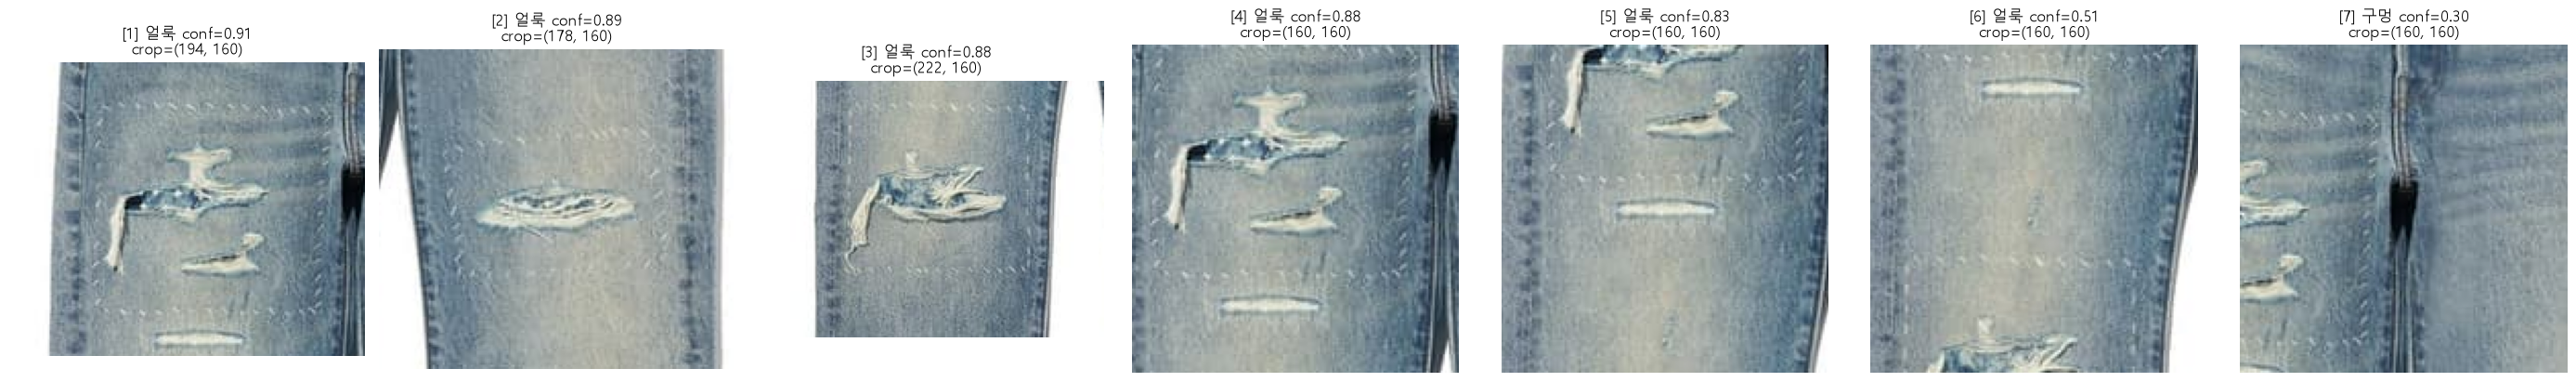

In [5]:
import matplotlib.pyplot as plt

crops = []
for inst in findings["instances"]:
    bbox = expand_bbox_to_min_size(inst["bbox"], CROP_PAD_RATIO, MIN_CROP_SIZE, image.size)
    crop = image.crop(bbox)
    crops.append((inst, bbox, crop))

fig, axes = plt.subplots(1, len(crops), figsize=(4 * len(crops), 4))
axes = [axes] if len(crops) == 1 else axes
for ax, (inst, bbox, crop) in zip(axes, crops):
    ax.imshow(crop)
    ax.set_title(f"[{inst['no']}] {inst['label']} conf={inst['confidence']:.2f}\ncrop={crop.size}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. 전체 findings VLM 추론

`IMAGE_STEM`의 모든 finding에 대해 크롭 + 설명을 나란히 본다.

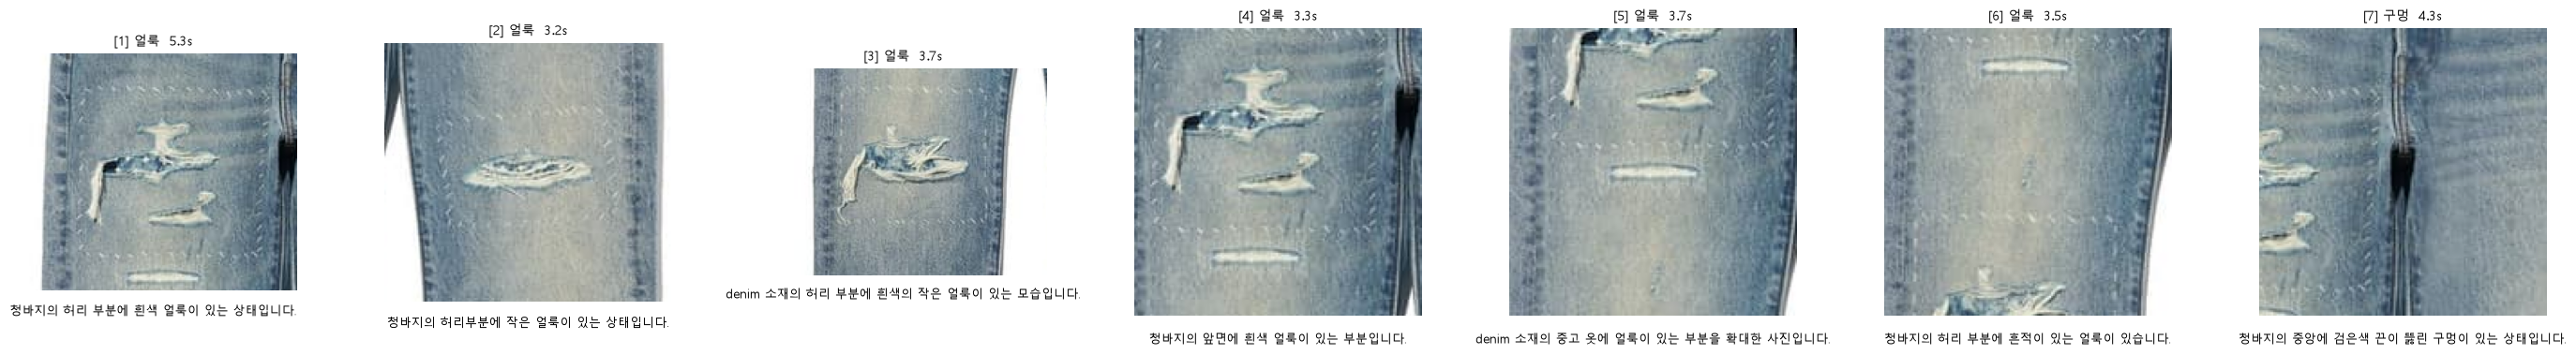

[1] 얼룩 -> 청바지의 허리 부분에 흰색 얼룩이 있는 상태입니다.
[2] 얼룩 -> 청바지의 허리부분에 작은 얼룩이 있는 상태입니다.
[3] 얼룩 -> denim 소재의 허리 부분에 흰색의 작은 얼룩이 있는 모습입니다.
[4] 얼룩 -> 청바지의 앞면에 흰색 얼룩이 있는 부분입니다.
[5] 얼룩 -> denim 소재의 중고 옷에 얼룩이 있는 부분을 확대한 사진입니다.
[6] 얼룩 -> 청바지의 허리 부분에 흔적이 있는 얼룩이 있습니다.
[7] 구멍 -> 청바지의 중앙에 검은색 끈이 뚫린 구멍이 있는 상태입니다.


In [6]:
results = []
for inst, bbox, crop in crops:
    prompt_text = build_prompt(inst["label"])
    _t0 = time.time()
    description = generate_from_image(bundle, crop, prompt_text)
    gen_s = time.time() - _t0
    results.append(
        {"no": inst["no"], "label": inst["label"], "bbox": bbox, "gen_s": gen_s, "description": description}
    )

fig, axes = plt.subplots(1, len(crops), figsize=(4 * len(crops), 5.5))
axes = [axes] if len(crops) == 1 else axes
for ax, (inst, bbox, crop), r in zip(axes, crops, results):
    ax.imshow(crop)
    ax.set_title(f"[{r['no']}] {r['label']}  {r['gen_s']:.1f}s", fontsize=10)
    ax.axis("off")
    ax.text(0.5, -0.06, r["description"], transform=ax.transAxes, ha="center", va="top", fontsize=9, wrap=True)
plt.tight_layout()
plt.show()

for r in results:
    print(f"[{r['no']}] {r['label']} -> {r['description']}")

## 5. 단일 finding 재실험 — 즉시 바꿔가며 반복 실행

`FOCUS_*` 값만 바꾸고 이 셀만 다시 실행하면 된다. 모델은 §1에서 이미 로드된 `bundle`을
그대로 쓰므로 재실행마다 몇 초(생성 시간)만 걸린다. `FOCUS_PROMPT_VARIANT`는 §0-2
`PROMPT_VARIANTS`의 키 중 하나를 쓴다.

gen=11.31s  variant=visual_detail  crop=(320, 320)  bbox=[59, 17, 379, 337]
prompt : 이 이미지는 중고 의류의 '얼룩' 하자 부분을 확대한 사진입니다. 색상, 모양, 크기, 위치적 특징 중 실제로 보이는 것만 한국어 한 문장으로 구체적으로 설명해 주세요. 보이지 않는 내용은 지어내지 마세요.
-> 파란색 청바지의 앞쪽 허리부분에 흰색과 파란색이 섞인 얼룩이 있는 부분이 있으며, 이 얼룩은 길고 좁은 형태로, 청바지의 오른쪽 허리 뒤쪽에 위치한 것으로 보입니다.


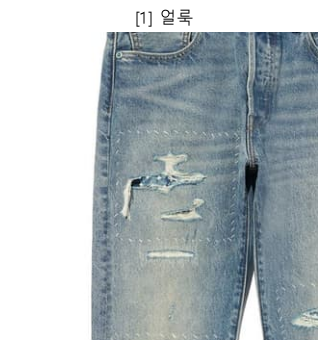

In [7]:
# 여기 값만 바꿔서 셀을 재실행한다.
FOCUS_NO = 1  # findings 중 확인할 번호(no)
FOCUS_PAD_RATIO = CROP_PAD_RATIO
FOCUS_MIN_SIZE = 320  # 예: 스모크 테스트보다 훨씬 큰 크롭으로 재시도
FOCUS_PROMPT_VARIANT = "visual_detail"

_inst = next(i for i in findings["instances"] if i["no"] == FOCUS_NO)
_bbox = expand_bbox_to_min_size(_inst["bbox"], FOCUS_PAD_RATIO, FOCUS_MIN_SIZE, image.size)
_crop = image.crop(_bbox)

_variant = PROMPT_VARIANTS[FOCUS_PROMPT_VARIANT]
if _variant is None:
    _prompt = build_defect_prompt(_inst["label"])
elif "{label}" in _variant:
    _prompt = _variant.format(label=_inst["label"])
else:
    _prompt = _variant

_t0 = time.time()
_description = generate_from_image(bundle, _crop, _prompt)
print(f"gen={time.time() - _t0:.2f}s  variant={FOCUS_PROMPT_VARIANT}  crop={_crop.size}  bbox={_bbox}")
print(f"prompt : {_prompt}")
print(f"-> {_description}")

plt.figure(figsize=(4, 4))
plt.imshow(_crop)
plt.axis("off")
plt.title(f"[{FOCUS_NO}] {_inst['label']}")
plt.show()

## 6. VRAM 최종 리포트

In [8]:
_vram_report("최종")

최종                   allocated=   2784.2 MB (2.72 GB)   peak=   2874.7 MB


(2784.1640625, 2874.69677734375)